## Лабораторная работа 213

Ряд Фурье для периодического сигнала $f(t)$ с периодом $T$ ($\Omega = \frac{2\pi}{T}$):
$$ f(t) = \frac{a_0}{2} + \sum_{n=1}^{\infty} (a_n \cos n\Omega t + b_n \sin n\Omega t) $$
Коэффициенты ряда Фурье:
$$ a_n = \frac{2}{T} \int_{-T/2}^{T/2} f(t) \cos n\Omega t \, dt \quad (n = 0, 1, 2, \dots) \qquad  b_n = \frac{2}{T} \int_{-T/2}^{T/2} f(t) \sin n\Omega t \, dt \quad (n = 1, 2, \dots) $$

Амплитуда и фаза $n$-й гармоники:
$$ C_n = \sqrt{a_n^2 + b_n^2}, \qquad \varphi_n = \arctan \frac{a_n}{b_n} \qquad y_n = C_n \sin(\omega_n t + \varphi_n) $$

Комплексная форма ряда Фурье:
$$ f(t) = \sum_{n=-\infty}^{\infty} S_n e^{i n \Omega t}, \qquad S_n = \frac{1}{T} \int_{-T/2}^{T/2} f(t) e^{-i n \Omega t} \, dt, \qquad C_n = 2|S_n| $$

Интеграл Фурье для одиночного импульса ($T \to \infty$):
$$ f(t) = \frac{1}{2\pi} \int_{-\infty}^{\infty} \rho(\omega) e^{i \omega t} \, d\omega, \qquad \rho(\omega) = \int_{-\infty}^{\infty} f(t) e^{-i \omega t} \, dt $$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Часть 1

In [2]:
from dataclasses import dataclass, field

@dataclass(slots=True)
class Envelope: 
    x: np.ndarray = field(default_factory=lambda: np.empty(0))
    y: np.ndarray = field(default_factory=lambda: np.empty(0))

def plot_graph(harmonics: pd.DataFrame, envelope: Envelope, level_e: float | None = None) -> None:
    plt.figure(figsize=(16, 9))
    plt.stem(
        harmonics["freq, kHz"],
        harmonics["A, mV"],
        linefmt="b-",
        markerfmt="bo",
        basefmt=" ",
        # label="Измеренные гармоники (n = 1, 3, 5, 7, 9)",
    )
    plt.plot(
        envelope.x, envelope.y, "r--", linewidth=2, label=r"Огибающая $A(\nu) \propto 1/\nu$"
    )
    if level_e is not None:
        plt.axhline(
            level_e,
            color="g",
            linestyle=":",
            label=f"Уровень $A_1/e$ ({level_e:.1f} мВ)",
        )

    plt.title("Спектр и огибающая прямоугольного сигнала (меандра)")
    plt.xlabel("Частота $\\nu$, кГц")
    plt.ylabel("Амплитуда $A$, мВ")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

##### Квадратный сигнал:

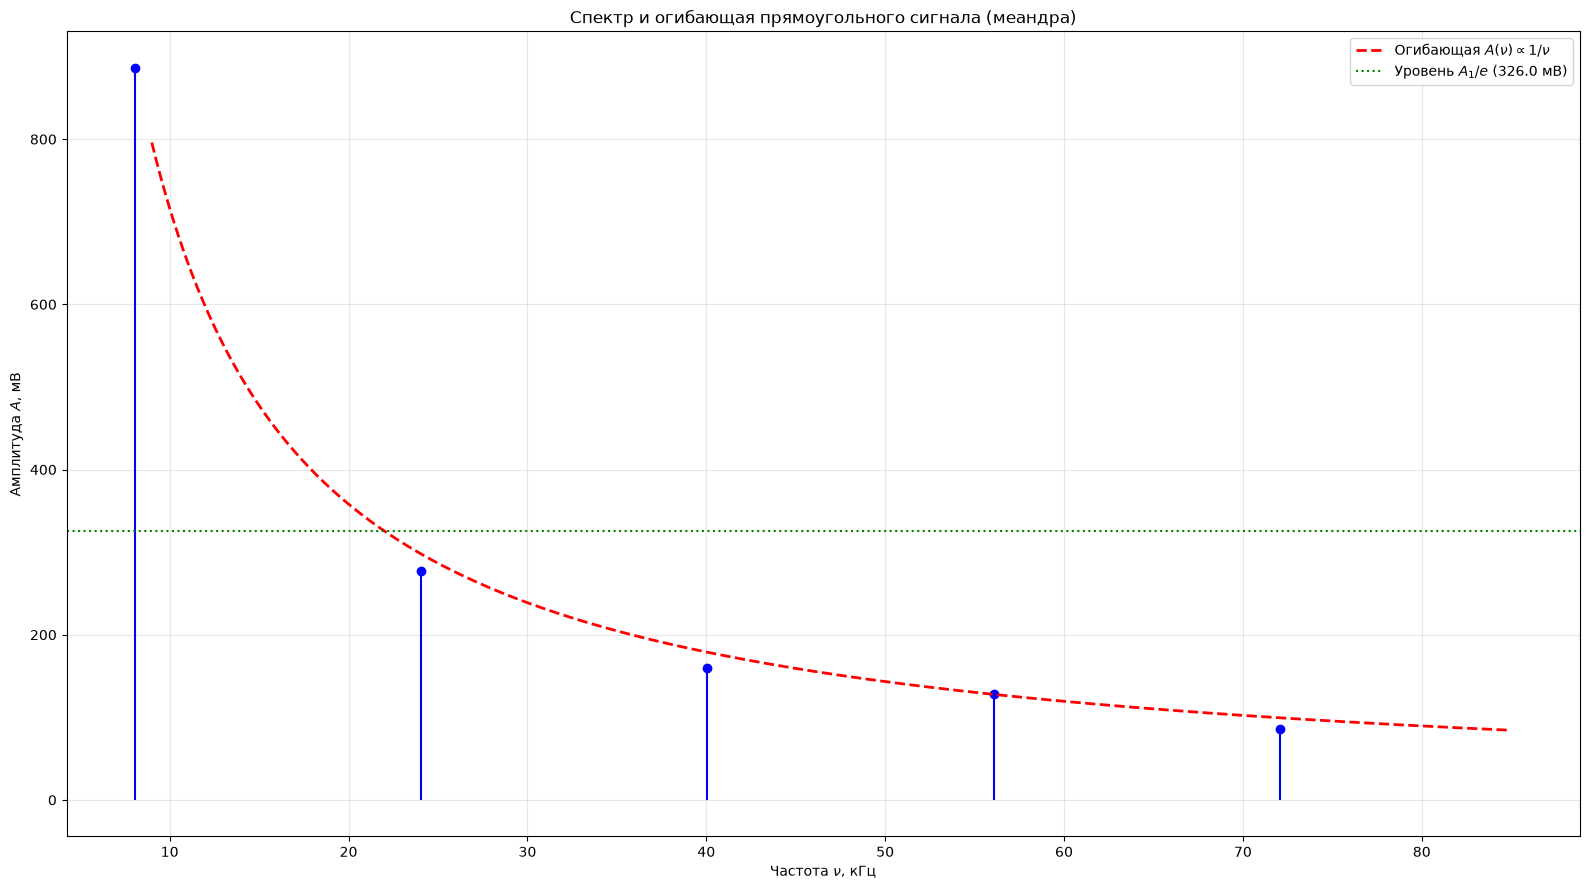

In [3]:
harmonics = pd.DataFrame({
    "freq, kHz": [8.084, 24.06, 40.03, 56.08, 72.05],
    "A, mV": [886.1, 277.6, 160.1, 128.1, 85.41],
    "n": [1, 3, 5, 7, 9],
}) # Гармоники
T = (127.3 - 2.732) * 1e-6  # период, с

# Теоретическая огибающая
f_grid = np.linspace(9, 85, 300)
f1 = harmonics["freq, kHz"].iloc[0]
A1 = harmonics["A, mV"].iloc[0]
envelope = A1 * f1 / f_grid

# Оценка ширины спектра по уровню 1/e
level_e = A1 / np.e

plot_graph(harmonics, Envelope(f_grid, envelope), level_e)

#### Синусоида:

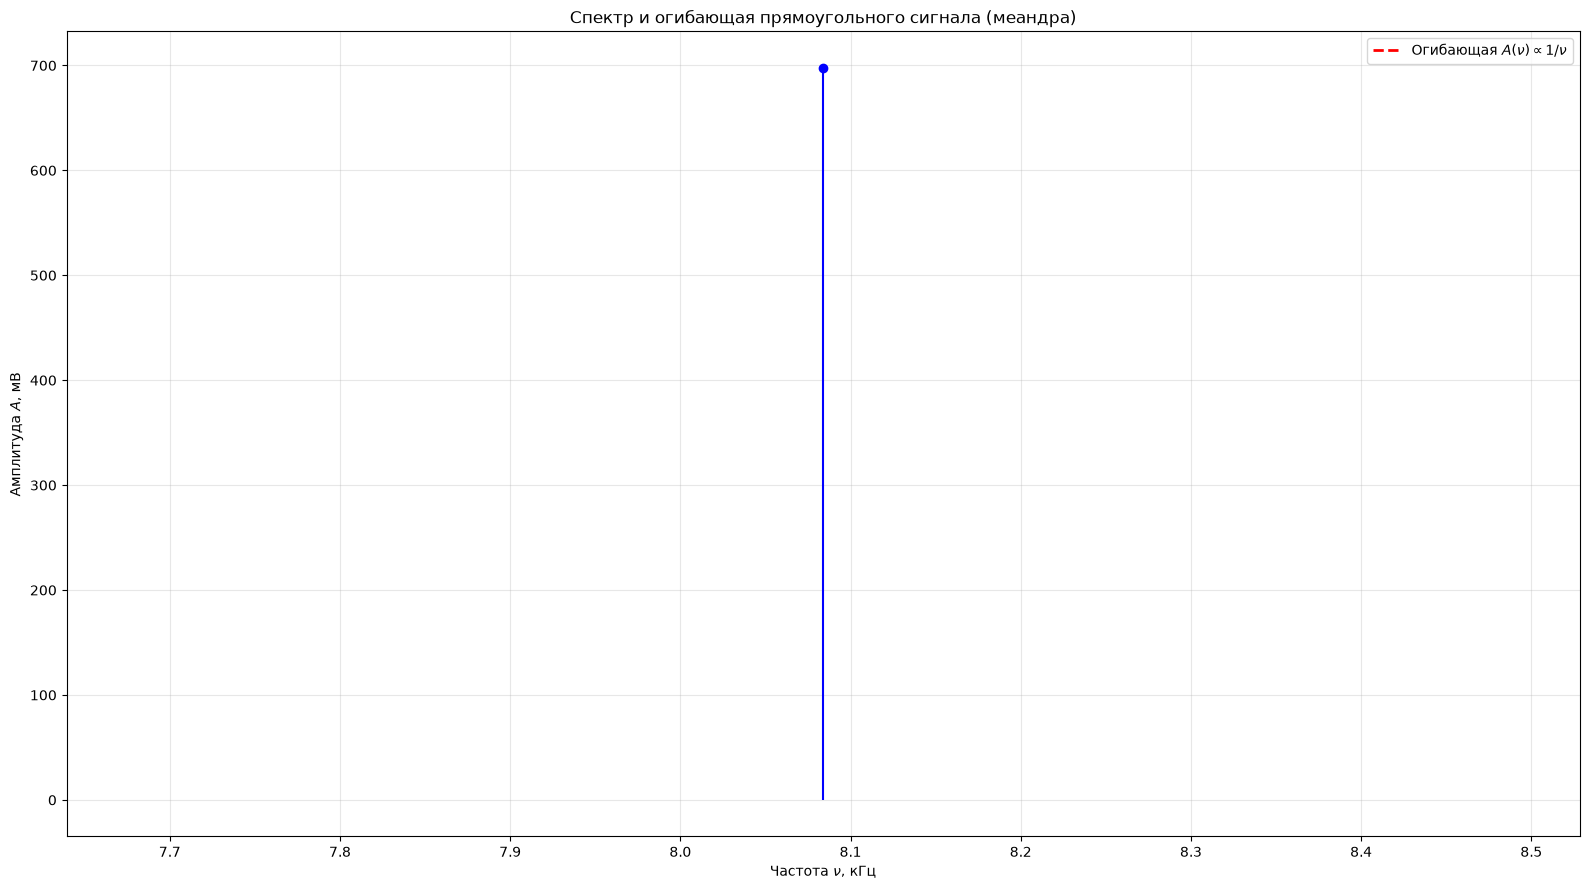

In [4]:
harmonics = pd.DataFrame({
    "freq, kHz": [8.084],
    "A, mV": [697.5],
})
T = (156.7 - 31.4) * 1e-6 

plot_graph(harmonics, Envelope())

### Треугольный сигнал

Период T = 125.30 мкс, длительность на полувысоте tau = 62.65 мкс
Ширина спектра (по уровню 1/e): df = 13.08 кГц
Произведение неопределённостей df * tau = 0.82


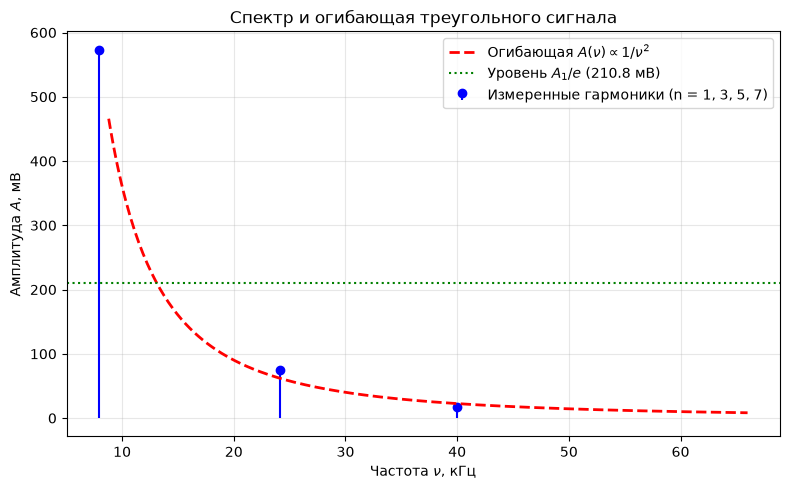

In [5]:
harmonics = pd.DataFrame({
    "freq, kHz": [7.935, 24.13, 39.96],
    "A, mV": [573.0, 74.73, 17.79],
})

T = (156.7 - 31.4) * 1e-6
tau = T / 2  # длительность импульса на полувысоте, с

# Добавлен индекс [0]
f_grid = np.linspace(8.8, 66, 300)
f1 = harmonics["freq, kHz"].iloc[0]
A1 = harmonics["A, mV"].iloc[0]
envelope = A1 * (f1 / f_grid) ** 2

# Оценка ширины спектра по уровню 1/e
level_e = A1 / np.e
df_exp = f1 * np.sqrt(np.e)

print(
    f"Период T = {T*1e6:.2f} мкс, длительность на полувысоте tau = {tau*1e6:.2f}"
    " мкс"
)
print(f"Ширина спектра (по уровню 1/e): df = {df_exp:.2f} кГц")
print(f"Произведение неопределённостей df * tau = {(df_exp * 1e3) * tau:.2f}")

# График
plt.figure(figsize=(8, 5))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1, 3, 5, 7)",
)
plt.plot(
    f_grid,
    envelope,
    "r--",
    linewidth=2,
    label=r"Огибающая $A(\nu) \propto 1/\nu^2$",
)
plt.axhline(
    level_e,
    color="g",
    linestyle=":",
    label=f"Уровень $A_1/e$ ({level_e:.1f} мВ)",
)

plt.title("Спектр и огибающая треугольного сигнала")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Пилообразный сигнал (повышающийся)

Период T = 124.95 мкс, длительность на полувысоте tau = 62.48 мкс
Ширина спектра (по уровню 1/e): df = 21.97 кГц
Произведение неопределённостей df * tau = 1.37


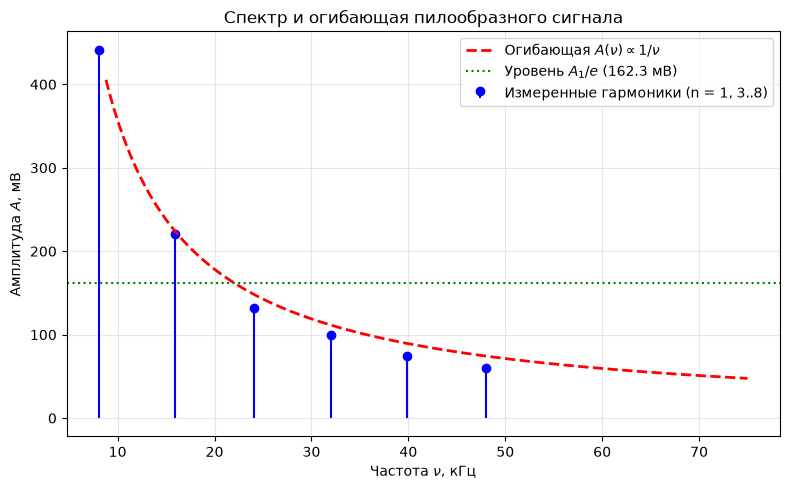

In [6]:
harmonics = pd.DataFrame({
    "freq, kHz": [8.084, 15.92, 24.06, 32.04, 39.88, 48.02],
    "A, mV":     [441.3, 220.6, 131.7, 99.64, 74.73, 60.5],
    "n": [1, 2, 3, 4, 5, 6],
})

T = (187.3 - 62.35) * 1e-6 
tau = T / 2  # длительность импульса на полувысоте, с

f1 = float(np.asarray(harmonics["freq, kHz"])[0])
A1 = float(np.asarray(harmonics["A, mV"])[0])

f_grid = np.linspace(8.8, 75, 300)
envelope = A1 * f1 / f_grid

# Оценка ширины спектра по уровню 1/e
level_e = A1 / np.e
df_exp = f1 * np.e

print(
    f"Период T = {T*1e6:.2f} мкс, длительность на полувысоте tau = {tau*1e6:.2f}"
    " мкс"
)
print(f"Ширина спектра (по уровню 1/e): df = {df_exp:.2f} кГц")
print(f"Произведение неопределённостей df * tau = {(df_exp * 1e3) * tau:.2f}")

# Построение графика
plt.figure(figsize=(8, 5))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1, 3..8)",
)
plt.plot(
    f_grid, envelope, "r--", linewidth=2, label=r"Огибающая $A(\nu) \propto 1/\nu$"
)
plt.axhline(
    level_e,
    color="g",
    linestyle=":",
    label=f"Уровень $A_1/e$ ({level_e:.1f} мВ)",
)

plt.title("Спектр и огибающая пилообразного сигнала")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Пилообразный сигнал (понижающийся)

Период T = 124.59 мкс, длительность на полувысоте tau = 62.29 мкс
Ширина спектра (по уровню 1/e): df = 21.37 кГц
Произведение неопределённостей df * tau = 1.33


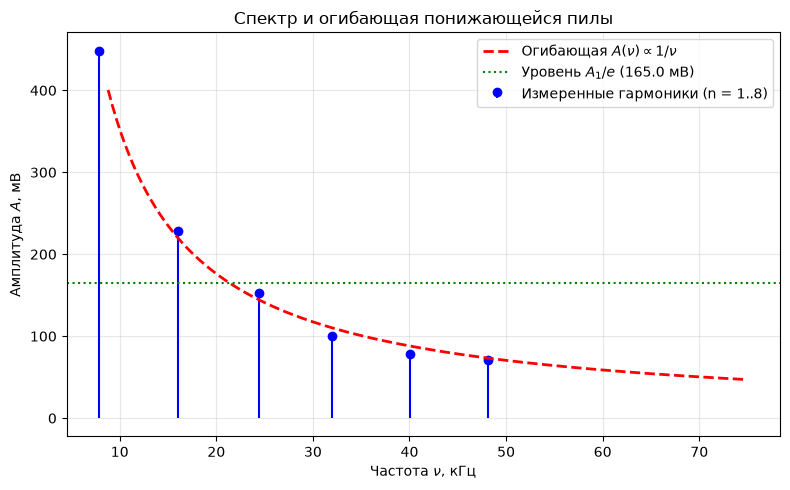

In [7]:
harmonics = pd.DataFrame({
    "freq, kHz": [7.86, 16.0, 24.43, 31.97, 40.03, 48.09],
    "A, mV": [448.4, 227.8, 153.0, 99.64, 78.29, 71.17],
    "n": [1, 2, 3, 4, 5, 6],
})

T = (127.7 - 3.114) * 1e-6 
tau = T / 2  # длительность импульса на полувысоте, с

f1 = float(np.asarray(harmonics["freq, kHz"]).item(0))
A1 = float(np.asarray(harmonics["A, mV"]).item(0))

# Теоретическая огибающая A(f) = A1 * f1 / f
f_grid = np.linspace(8.8, 75, 300)
envelope = A1 * f1 / f_grid

# Оценка ширины спектра по уровню 1/e
level_e = A1 / np.e
df_exp = f1 * np.e

print(
    f"Период T = {T*1e6:.2f} мкс, длительность на полувысоте tau = {tau*1e6:.2f}"
    " мкс"
)
print(f"Ширина спектра (по уровню 1/e): df = {df_exp:.2f} кГц")
print(f"Произведение неопределённостей df * tau = {(df_exp * 1e3) * tau:.2f}")

# Построение графика
plt.figure(figsize=(8, 5))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1..8)",
)
plt.plot(
    f_grid, envelope, "r--", linewidth=2, label=r"Огибающая $A(\nu) \propto 1/\nu$"
)
plt.axhline(
    level_e,
    color="g",
    linestyle=":",
    label=f"Уровень $A_1/e$ ({level_e:.1f} мВ)",
)

plt.title("Спектр и огибающая понижающейся пилы")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Гаусс:

Период T = 125.35 мкс
Ширина спектра по уровню 1/e (из аппроксимации): df = 15.97 кГц
Оценка полуширины импульса tau = 19.93 мкс
Произведение неопределённостей df * tau = 0.32


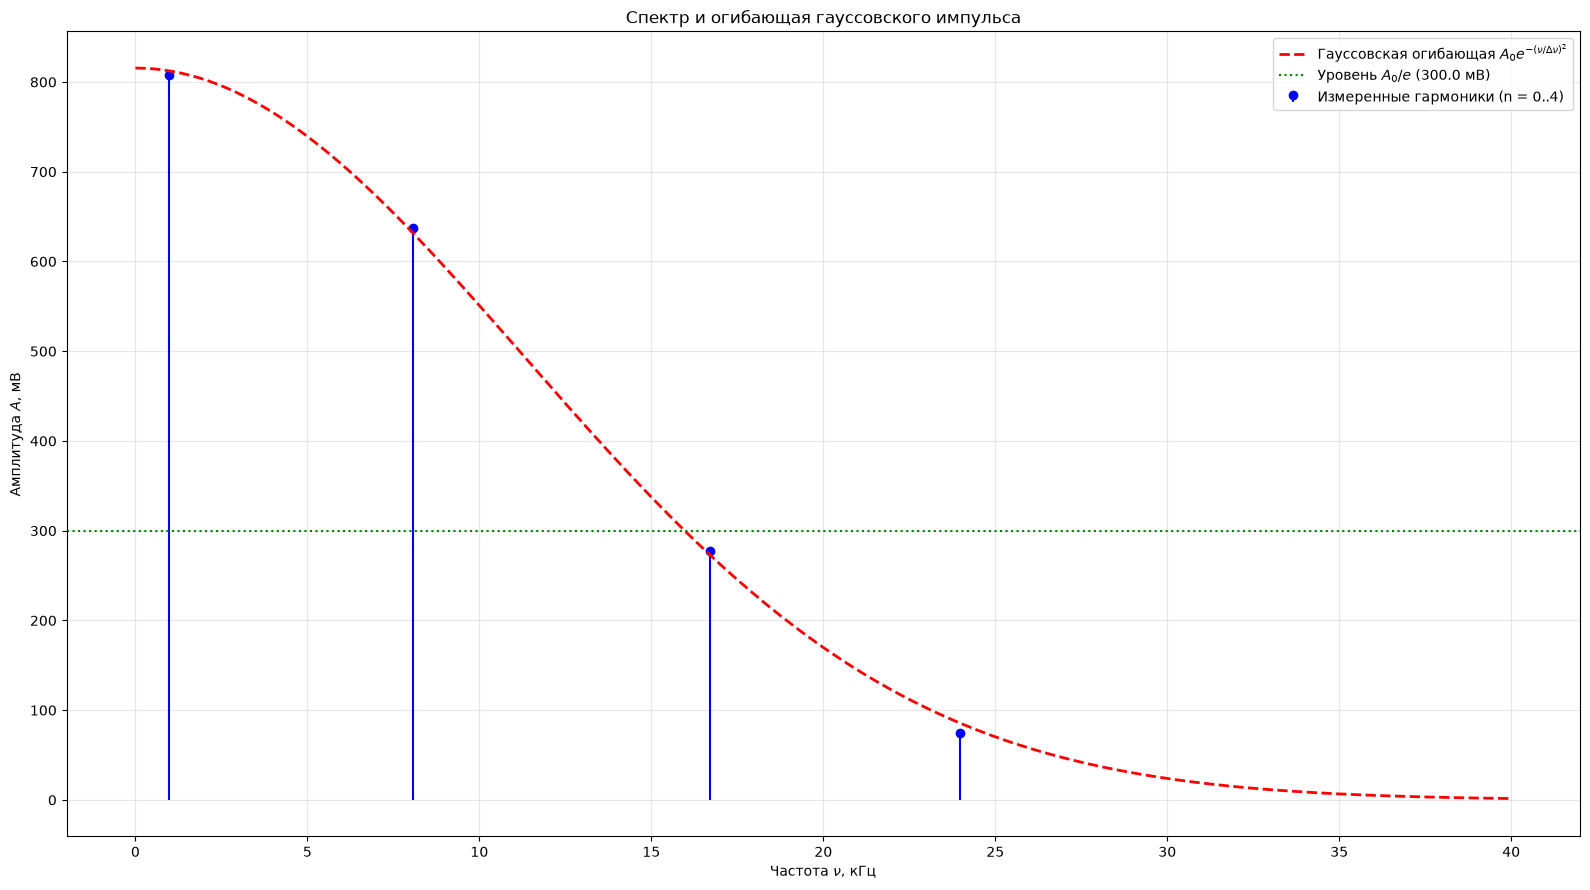

Измеренная длительность на полувысоте tau_0.5 = 81.47 мкс
Ширина спектра на полувысоте df_0.5 = 13.29 кГц
Экспериментальное произведение неопределённостей df_0.5 * tau_0.5 = 1.08 (теория ~ 0.44)


In [9]:
from scipy.optimize import curve_fit

harmonics = pd.DataFrame({
    "freq, kHz": [0.97, 8.084, 16.7, 23.98],
    "A, mV": [807.8, 637.0, 277.0, 74.73],
    "n": [1, 2, 3, 4]
})

T = (142.6 - 17.25) * 1e-6


# Аппроксимация огибающей гауссовской кривой A(f) = A0 * exp(-(f / df)^2)
def gauss_env(f, A0, df):
  return A0 * np.exp(-((f / df) ** 2))


popt, _ = curve_fit(
    gauss_env, harmonics["freq, kHz"], harmonics["A, mV"], p0=(804.3, 16.0)
)
A0_fit, df_fit = popt

f_grid = np.linspace(0, 40, 300)
envelope = gauss_env(f_grid, A0_fit, df_fit)

# Оценка длительности импульса по соотношению неопределённостей
# Для гауссовского импульса exp(-(t/tau)^2) и спектра exp(-(w*tau/2)^2): df * tau = 1 / pi
tau_est = 1 / (np.pi * df_fit * 1e3)
level_e = A0_fit / np.e

print(f"Период T = {T*1e6:.2f} мкс")
print(
    f"Ширина спектра по уровню 1/e (из аппроксимации): df = {df_fit:.2f} кГц"
)
print(f"Оценка полуширины импульса tau = {tau_est*1e6:.2f} мкс")
print(
    f"Произведение неопределённостей df * tau = {(df_fit * 1e3) * tau_est:.2f}"
)

# График
plt.figure(figsize=(16, 9))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 0..4)",
)
plt.plot(
    f_grid,
    envelope,
    "r--",
    linewidth=2,
    label=r"Гауссовская огибающая $A_0 e^{-(\nu/\Delta\nu)^2}$",
)
plt.axhline(
    level_e,
    color="g",
    linestyle=":",
    label=f"Уровень $A_0/e$ ({level_e:.1f} мВ)",
)

plt.title("Спектр и огибающая гауссовского импульса")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
# Подставьте ваши измеренные времена (в мкс) на уровне половины пика:
t1 = -192.6  # левый фронт на 0.5 от пика, мкс
t2 = -111.13  # правый фронт на 0.5 от пика, мкс
tau_half = (t2 - t1) * 1e-6  # длительность на полувысоте, с

# Ширина спектра на полувысоте (0.5 от A0) из вашей аппроксимации (df_fit = 16.0 кГц):
df_half = df_fit * np.sqrt(np.log(2))  # ~ 13.3 кГц

print(f"Измеренная длительность на полувысоте tau_0.5 = {tau_half*1e6:.2f} мкс")
print(f"Ширина спектра на полувысоте df_0.5 = {df_half:.2f} кГц")
print(
    "Экспериментальное произведение неопределённостей df_0.5 * tau_0.5 ="
    f" {(df_half * 1e3) * tau_half:.2f} (теория ~ 0.44)"
)


### Часть 2

#### Прямоугольный сигнал. Скважность 4

Таблица сравнения относительных амплитуд (T/tau = 4, без 0-й гармоники):
 n  freq, kHz  (Cn/C1)_эксп  (Cn/C1)_теор
 1      15.92         1.000         1.000
 2      32.12         0.653         0.707
 3      47.94         0.341         0.333

Ширина главного лепестка спектра: df = 47.76 кГц (по эксперименту 3-я гармоника на 47.94 кГц)
Произведение неопределённостей df * tau (номинальное) = 0.68
Произведение неопределённостей df * tau (измеренное) = 0.58


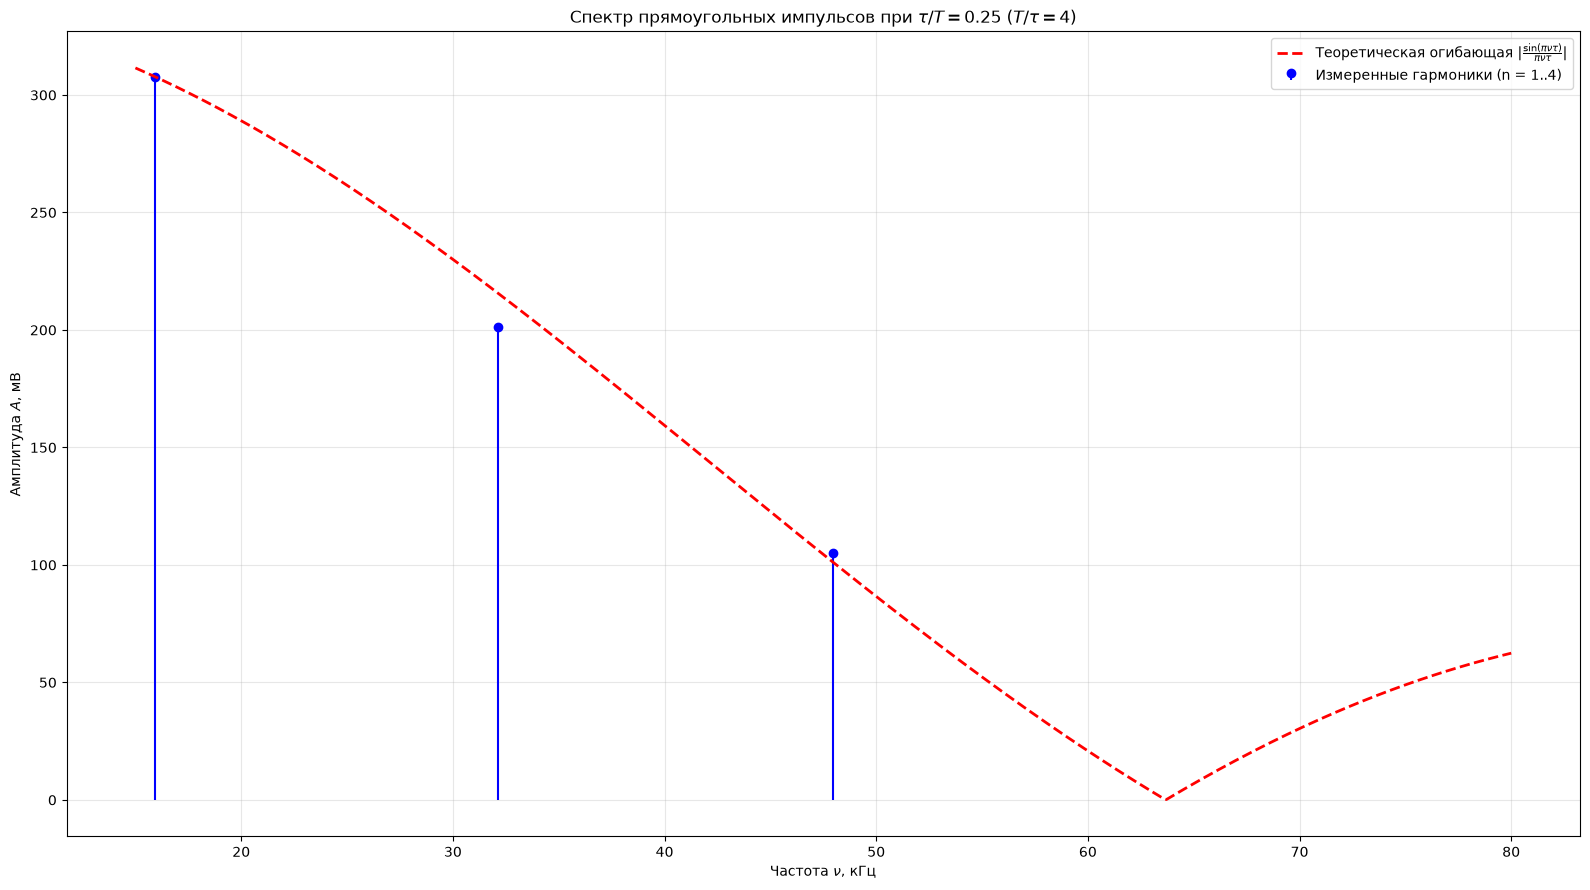

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

harmonics = pd.DataFrame({
    "freq, kHz": (15.92, 32.12, 47.94),
    "A, mV": (307.8, 201.1, 105.0),
    "n": (1, 2, 3),
})

T = (61.59 - 5.0) * 1e-6 
tau = (14.58 - 2.35) * 1e-6 
duty = 0.25  # заданный коэффициент заполнения tau / T = 1/4

f1 = float(np.asarray(harmonics["freq, kHz"]).item(0))  # 18.09 кГц
A1 = float(np.asarray(harmonics["A, mV"]).item(0))  # 306.0 мВ

# Амплитуда огибающей в нуле (восстановлена по 1-й гармонике)
A_env0 = A1 * (np.pi * duty) / np.sin(np.pi * duty)

# Теоретическая огибающая |sin(pi * f * tau) / (pi * f * tau)| при tau = 0.25 * T
f_grid = np.linspace(15, 80, 400)
x = np.pi * (f_grid / f1) * duty
envelope = A_env0 * np.abs(np.sin(x) / x)

# Таблица сравнения относительных амплитуд (n = 1..4)
n_arr = np.asarray(harmonics["n"])
rel_exp = np.asarray(harmonics["A, mV"]) / A1
rel_theor = (1 / n_arr) * np.abs(
    np.sin(np.pi * n_arr * duty) / np.sin(np.pi * duty)
)

df_compare = pd.DataFrame({
    "n": n_arr,
    "freq, kHz": harmonics["freq, kHz"],
    "(Cn/C1)_эксп": np.round(rel_exp, 3),
    "(Cn/C1)_теор": np.round(rel_theor, 3),
})
print("Таблица сравнения относительных амплитуд (T/tau = 4, без 0-й гармоники):")
print(df_compare.to_string(index=False))

# Оценка ширины спектра (до первого нуля огибающей f_zero = 4 * f1)
df_spec = 3 * f1  # ~ 63.6 кГц
tau_nom = duty * T  # номинальная длительность 0.25 * T 
print(
    f"\nШирина главного лепестка спектра: df = {df_spec:.2f} кГц (по"
    " эксперименту 3-я гармоника на 47.94 кГц)"
)
print(
    "Произведение неопределённостей df * tau (номинальное) ="
    f" {(df_spec * 1e3) * tau_nom:.2f}"
)
print(
    "Произведение неопределённостей df * tau (измеренное) ="
    f" {(df_spec * 1e3) * tau:.2f}"
)

# Построение графика
plt.figure(figsize=(16, 9))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1..4)",
)
plt.plot(
    f_grid,
    envelope,
    "r--",
    linewidth=2,
    label=r"Теоретическая огибающая $|\frac{\sin(\pi \nu \tau)}{\pi \nu \tau}|$",
)

plt.title(r"Спектр прямоугольных импульсов при $\tau/T = 0.25$ ($T/\tau = 4$)")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


#### Прямоугольные импульсы. Скважность 4/3

Таблица сравнения относительных амплитуд (T/tau = 4/3):
 n  freq, kHz  (Cn/C1)_эксп  (Cn/C1)_теор
 1      15.77         1.000         1.000
 2      32.04         0.655         0.707
 3      48.02         0.305         0.333


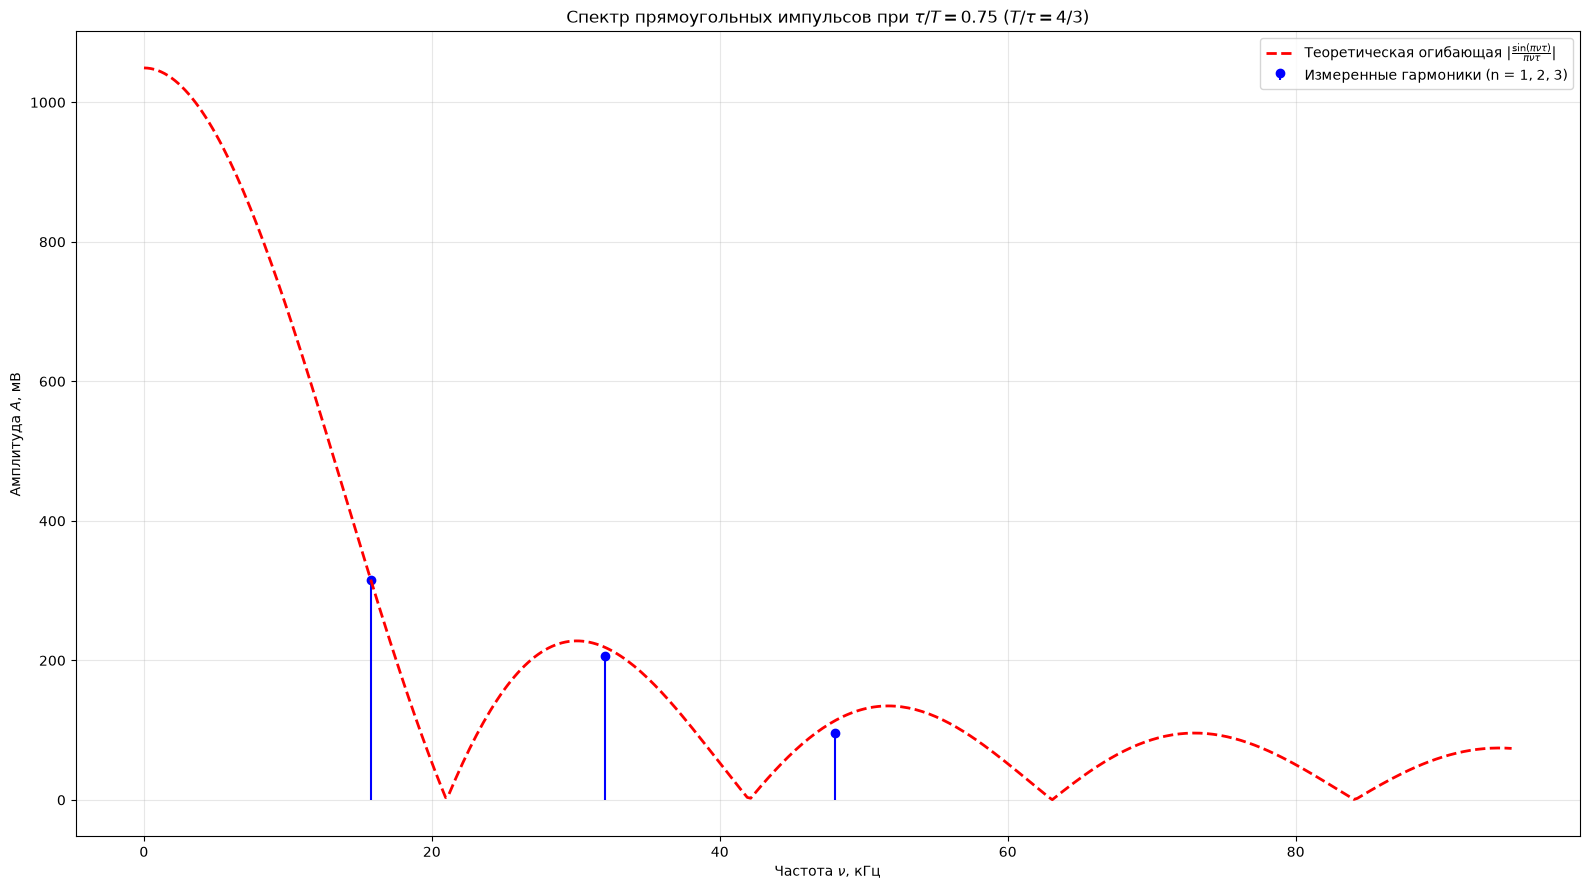

In [6]:
harmonics = pd.DataFrame({
    "freq, kHz": [15.77, 32.04, 48.02],
    "A, mV": [314.9, 206.4, 96.09],
    "n": (1, 2, 3)
})

T = (62.73 - 0) * 1e-6 
tau = (46.3 - 2.732) * 1e-6  
duty = 0.75  # заданный коэффициент заполнения tau / T = 3/4

f1 = float(np.asarray(harmonics["freq, kHz"]).item(0))  # 15.77 кГц
A1 = float(np.asarray(harmonics["A, mV"]).item(0))  # 314.9 мВ

# Амплитуда огибающей в нуле
A_env0 = A1 * (np.pi * duty) / np.sin(np.pi * duty)

# Теоретическая огибающая |sin(pi * f * tau) / (pi * f * tau)| при tau = 0.75 * T
f_grid = np.linspace(0.01, 95, 400)
x = np.pi * (f_grid / f1) * duty
envelope = A_env0 * np.abs(np.sin(x) / x)

# Таблица сравнения относительных амплитуд (n = 1, 2. 3)
n_arr = np.asarray(harmonics["n"])
rel_exp = np.asarray(harmonics["A, mV"]) / A1
rel_theor = (1 / n_arr) * np.abs(
    np.sin(np.pi * n_arr * duty) / np.sin(np.pi * duty)
)

df_compare = pd.DataFrame({
    "n": n_arr,
    "freq, kHz": harmonics["freq, kHz"],
    "(Cn/C1)_эксп": np.round(rel_exp, 3),
    "(Cn/C1)_теор": np.round(rel_theor, 3),
})
print("Таблица сравнения относительных амплитуд (T/tau = 4/3):")
print(df_compare.to_string(index=False))

# Построение графика
plt.figure(figsize=(16, 9))
plt.stem(
    harmonics["freq, kHz"],
    harmonics["A, mV"],
    linefmt="b-",
    markerfmt="bo",
    basefmt=" ",
    label="Измеренные гармоники (n = 1, 2, 3)",
)
plt.plot(
    f_grid,
    envelope,
    "r--",
    linewidth=2,
    label=r"Теоретическая огибающая $|\frac{\sin(\pi \nu \tau)}{\pi \nu \tau}|$",
)

plt.title(r"Спектр прямоугольных импульсов при $\tau/T = 0.75$ ($T/\tau = 4/3$)")
plt.xlabel("Частота $\\nu$, кГц")
plt.ylabel("Амплитуда $A$, мВ")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Часть 3

#### Прямоугольный сигнал. Скважность 4/3 и 4

Паразитная ёмкость C_пар ≈ 83 пФ

=== Скважность T/tau = 4/3 ===
    Цепочка  f_ср эксп, кГц  f_ср теор (C), кГц  f_ср теор (C+C_пар), кГц
C1 = 100 пФ            87.6               159.2                      86.9
C2 = 200 пФ            57.1                79.6                      56.2
C3 = 530 пФ            29.0                30.0                      26.0


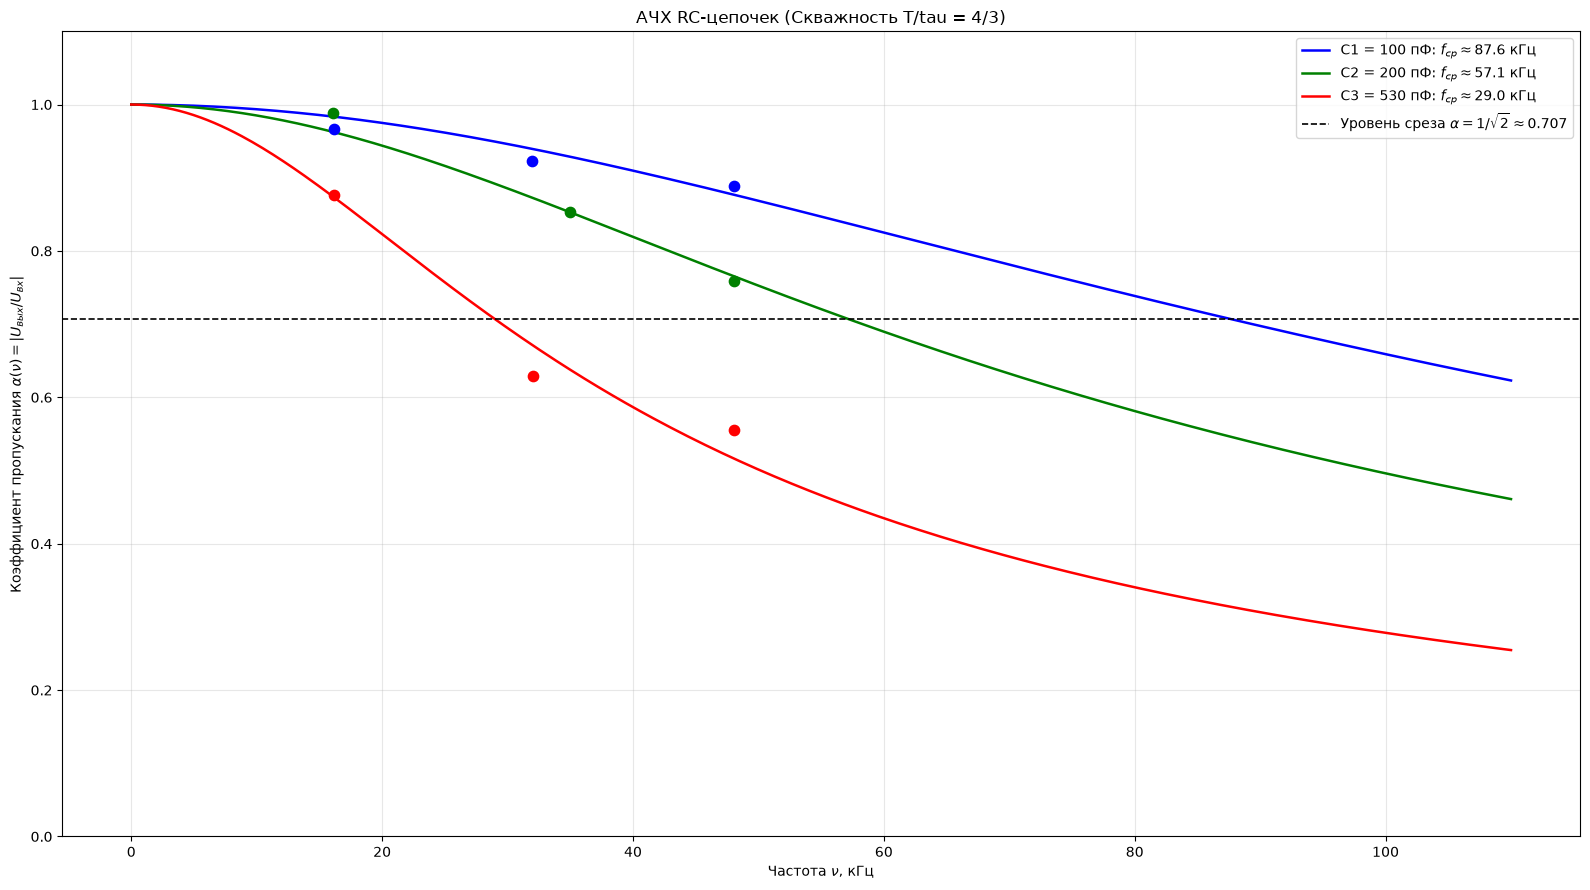


=== Скважность T/tau = 4 (duty = 0.25) ===
    Цепочка  f_ср эксп, кГц  f_ср теор (C), кГц  f_ср теор (C+C_пар), кГц
C1 = 100 пФ            75.9               159.2                      86.9
C2 = 200 пФ            55.1                79.6                      56.2
C3 = 530 пФ            25.3                30.0                      26.0


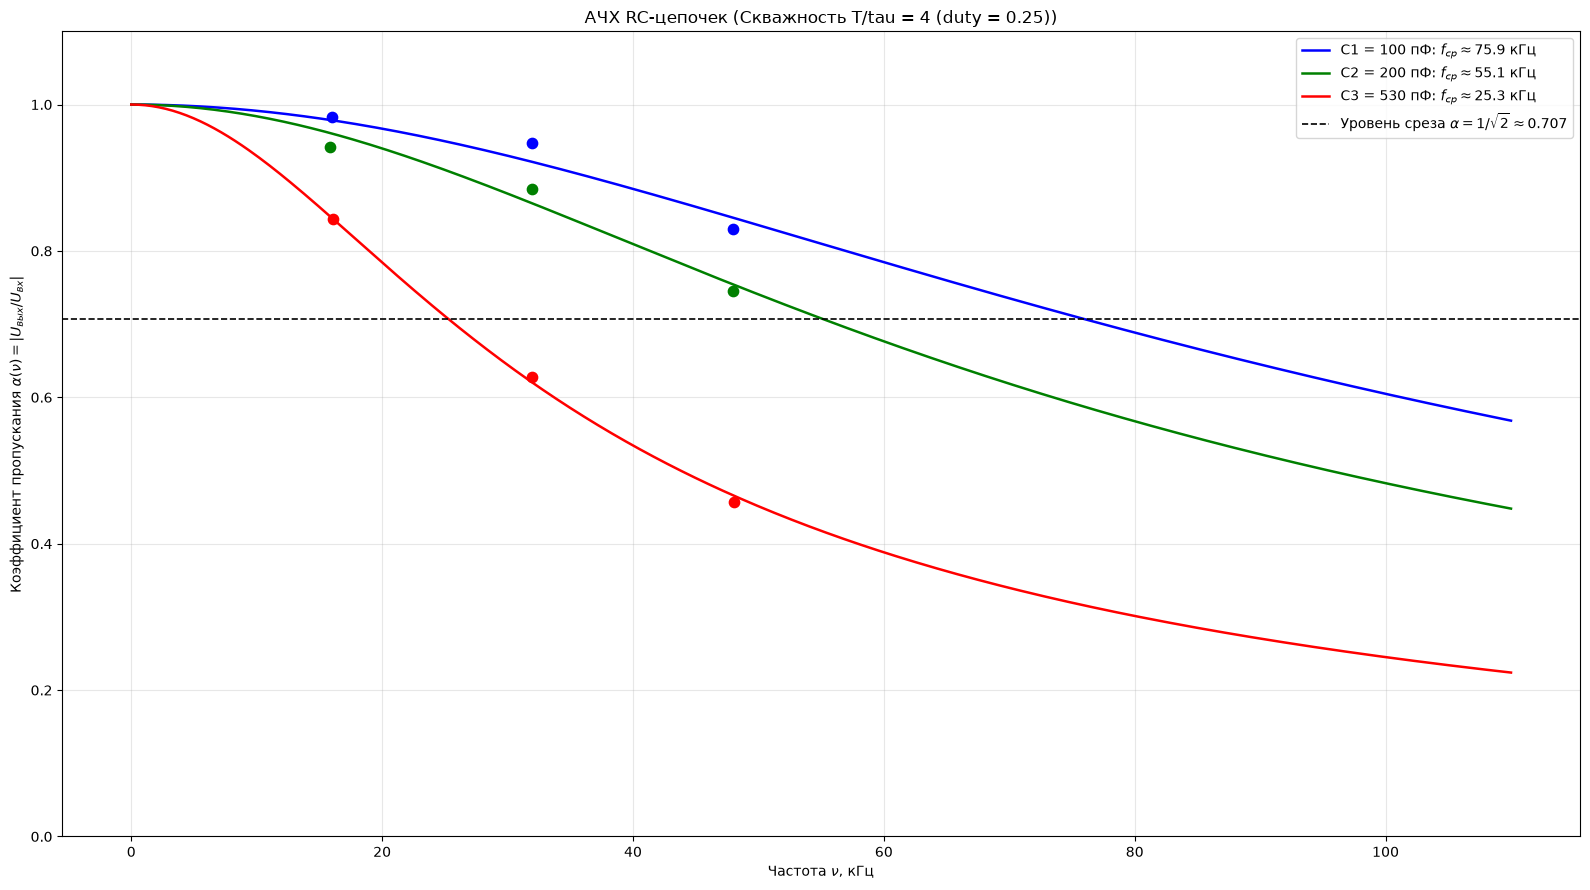

In [11]:
from dataclasses import dataclass
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit, least_squares

R_OHM = 10e3  # Сопротивление цепочки R = 10 кОм


@dataclass
class ExperimentWithC:
  C: float  # Ёмкость, Ф
  name: str  # Название цепочки для легенды
  harmonics: pd.DataFrame  # Выходной спектр
  A_in: np.ndarray  # Входные амплитуды из Задачи 2, мВ
  T: float  # Период, с

  def get_alpha(self) -> np.ndarray:
    """Коэффициент пропускания |U_вых / U_вх|."""
    return np.asarray(self.harmonics["A, mV"]) / self.A_in

  def theoretical_f_cut_khz(self, c_par: float = 0.0) -> float:
    """Теоретическая частота среза f_ср = 1 / (2π R (C + C_пар)), кГц."""
    return (1.0 / (2.0 * np.pi * R_OHM * (self.C + c_par))) / 1e3

A_IN_DUTY_43 = np.array((314.9, 206.4, 96.09))
A_IN_DUTY_4 = np.array((307.8, 201.1, 105.0))

exp_duty2 = (
    ExperimentWithC(
        C=100e-12,
        name="C1 = 100 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (16.15, 31.97, 48.02),
            "A, mV": (304.3, 190.4, 85.41),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_43,
        T=(66.17 - 3.879) * 1e-6,
    ),
    ExperimentWithC(
        C=200e-12,
        name="C2 = 200 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (16.07, 34.97, 48.02),
            "A, mV": (311.4, 176.2, 72.95),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_43,
        T=(107.4 - 43.63) * 1e-6,
    ),
    ExperimentWithC(
        C=530e-12,
        name="C3 = 530 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (16.15, 32.04, 48.02),
            "A, mV": (275.8, 129.9, 53.38),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_43,
        T=(104.8 - 42.1) * 1e-6,
    ),
)

exp_duty4 = (
    ExperimentWithC(
        C=100e-12,
        name="C1 = 100 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (16.0, 31.97, 47.94),
            "A, mV": (302.5, 190.4, 87.19),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_4,
        T=(58.6 - 0) * 1e-6,
    ),
    ExperimentWithC(
        C=200e-12,
        name="C2 = 200 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (15.85, 31.97, 47.94),
            "A, mV": (290.0, 177.9, 78.29),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_4,
        T=(63.4 - 0) * 1e-6,
    ),
    ExperimentWithC(
        C=530e-12,
        name="C3 = 530 пФ",
        harmonics=pd.DataFrame({
            "freq, kHz": (16.07, 31.97, 48.02),
            "A, mV": (259.8, 126.3, 48.04),
            "n": (1, 2, 3),
        }),
        A_in=A_IN_DUTY_4[:3],
        T=(73.05 - 9.994) * 1e-6,
    ),
)


def ach_curve(f: np.ndarray, f_cut: float) -> np.ndarray:
  return 1.0 / np.sqrt(1.0 + (f / f_cut) ** 2)

def fit_c_par(blocks) -> float:
    def residuals(p):
        r = []
        for block in blocks:
            for e in block:
                f = np.asarray(e.harmonics["freq, kHz"])
                r += list(ach_curve(f, e.theoretical_f_cut_khz(p[0] * 1e-12)) - e.get_alpha())
        return r
    return least_squares(residuals, [50.0]).x[0] * 1e-12

C_PAR = fit_c_par((exp_duty2, exp_duty4))
print(f"Паразитная ёмкость C_пар ≈ {C_PAR*1e12:.0f} пФ")   # ≈ 85 пФ

def analyze_block(experiments: tuple[ExperimentWithC, ...], title: str) -> None:
  f_grid = np.linspace(0, 110, 400)
  colors = ("b", "g", "r")
  summary = []
  

  plt.figure(figsize=(16,9))

  for exp, color in zip(experiments, colors):
    freq = np.asarray(exp.harmonics["freq, kHz"])
    alpha = exp.get_alpha()

    # Аппроксимация АЧХ для определения частоты среза
    popt, _ = curve_fit(ach_curve, freq, alpha, p0=(50.0,))
    f_cut_exp = float(popt.item(0))
    f_cut_theor = exp.theoretical_f_cut_khz()

    summary.append({
        "Цепочка": exp.name,
        "f_ср эксп, кГц": round(f_cut_exp, 1),
        "f_ср теор (C), кГц": round(f_cut_theor, 1),
        "f_ср теор (C+C_пар), кГц": round(exp.theoretical_f_cut_khz(C_PAR), 1),
    })

    plt.scatter(freq, alpha, color=color, s=55, zorder=3)
    plt.plot(
        f_grid,
        ach_curve(f_grid, f_cut_exp),
        color=color,
        linewidth=1.8,
        label=f"{exp.name}: $f_{{ср}} \\approx {f_cut_exp:.1f}$ кГц",
    )

  plt.axhline(
      1.0 / np.sqrt(2.0),
      color="k",
      linestyle="--",
      linewidth=1.2,
      label=r"Уровень среза $\alpha = 1/\sqrt{2} \approx 0.707$",
  )

  print(f"\n=== {title} ===")
  print(pd.DataFrame(summary).to_string(index=False))

  plt.title(f"АЧХ RC-цепочек ({title})")
  plt.xlabel("Частота $\\nu$, кГц")
  plt.ylabel(r"Коэффициент пропускания $\alpha(\nu) = |U_{вых}/U_{вх}|$")
  plt.ylim(0, 1.1)
  plt.grid(True, alpha=0.3)
  plt.legend()
  plt.tight_layout()
  plt.show()


analyze_block(exp_duty2, "Скважность T/tau = 4/3")
analyze_block(exp_duty4, "Скважность T/tau = 4 (duty = 0.25)")
